# Proyek Analisis Data: Bike Sharing
- **Nama:** Rahimah
- **Email:** ds296b6x1487@student.devacademy.id
- **ID Dicoding:** DS296b6x1487

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh musim (season) dan kondisi cuaca (weathersit) terhadap total penyewaan sepeda harian di Washington D.C. selama periode 2011–2012?
- **Pertanyaan 2:** Bagaimana pola penyewaan sepeda per jam pada hari kerja dibandingkan hari libur selama 2011–2012, dan bagaimana perbedaan kontribusi pengguna casual dan registered pada jam-jam sibuk tersebut?

## Import Semua Packages/Library yang Digunakan

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [6]:
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print('day:', day_df.shape)
print('hour:', hour_df.shape)
day_df.head()
hour_df.head()

day: (731, 16)
hour: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset Bike Sharing dari Capital Bikeshare, Washington D.C. berhasil dimuat dari dua file.
- day.csv berisi 731 baris (data harian 2011–2012) dengan 16 kolom, dipakai untuk menjawab Pertanyaan 1.
- hour.csv berisi 17.379 baris (data per jam 2011–2012) dengan 17 kolom, dipakai untuk menjawab Pertanyaan 2.
- Kedua file memiliki kolom cnt sebagai total penyewaan sepeda, yang merupakan variabel utama analisis ini.

### Assessing Data

#### Identifying ... problem

In [7]:
print("=== day_df ===")
print(day_df.info())
print(day_df.isna().sum())
print("Duplikat:", day_df.duplicated().sum())

print("\n=== hour_df ===")
print(hour_df.info())
print(hour_df.isna().sum())
print("Duplikat:", hour_df.duplicated().sum())

print("\nJam yang seharusnya:", 731 * 24)
print("Jam yang ada:", len(hour_df))
print("Jam yang hilang:", 731 * 24 - len(hour_df))

print("\nweathersit day:", day_df['weathersit'].value_counts().sort_index().to_dict())
print("weathersit hour:", hour_df['weathersit'].value_counts().sort_index().to_dict())
print(day_df.describe().T)

=== day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None
instant       0
dteday        0
season        0
yr            0
mnth     

**Steps to Take:**
- Ubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada `day_df` dan `hour_df`, agar bisa dipakai untuk analisis berdasarkan waktu.
- Petakan kolom berkode menjadi label yang bermakna: `season` (1=Spring, 2=Summer, 3=Fall, 4=Winter), `yr` (0=2011, 1=2012), `weathersit` (1=Clear, 2=Mist, 3=Light Rain/Snow, 4=Heavy Rain), dan `weekday` (0=Sunday sampai 6=Saturday).
- Kembalikan kolom ternormalisasi ke satuan aslinya sesuai Readme: `temp * 41` (°C), `atemp * 50` (°C), `hum * 100` (%), dan `windspeed * 67`.
- Hapus kolom `instant` karena hanya nomor urut baris dan tidak dipakai dalam analisis.
- Tidak ada baris yang dibuang atau diisi, karena tidak ditemukan missing value dan duplikat.
- Jam yang hilang di `hour.csv` (165 jam) tidak diimputasi, hanya dicatat sebagai keterbatasan data.

**Insight:** (Opsional)
- Kedua dataset sudah lengkap dan bersih dari sisi missing value dan duplikat: `day_df` berisi 731 baris dan 16 kolom, `hour_df` berisi 17.379 baris dan 17 kolom, semuanya non-null.
- Total penyewaan harian (`cnt`) rata-rata 4.504 sepeda per hari (median 4.548, rentang 22–8.714). Pengguna `registered` jauh lebih dominan daripada `casual`, dengan rata-rata 3.656 berbanding 848 per hari.
- Sebagian besar hari ber cuaca cerah: pada `day_df`, `weathersit` 1 (Clear) ada 463 hari, 2 (Mist) 247 hari, dan 3 (Light Rain/Snow) 21 hari. Pada `hour_df`, kondisi 4 (Heavy Rain) hanya muncul 3 jam, sehingga kelompok ini sangat kecil dan perlu hati-hati saat diinterpretasikan.
- Ditemukan 4 masalah utama yang harus diperbaiki di tahap Cleaning: `dteday` masih bertipe teks, kolom kategorikal masih berupa angka kode, kolom suhu/kelembapan/kecepatan angin masih ternormalisasi (0–1), dan `hour.csv` kekurangan 165 jam dari total yang seharusnya 17.544 jam.

### Cleaning Data

#### Fixing ... problem

In [8]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Clear', 2: 'Mist', 3: 'Light Rain/Snow', 4: 'Heavy Rain'}
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
               4: 'Thursday', 5: 'Friday', 6: 'Saturday'}

def clean_bike_df(df):
    df = df.copy()
    df['dteday'] = pd.to_datetime(df['dteday'])
    df['year'] = df['yr'] + 2011
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['temp_c'] = df['temp'] * 41
    df['atemp_c'] = df['atemp'] * 50
    df['hum_pct'] = df['hum'] * 100
    df['windspeed_val'] = df['windspeed'] * 67
    df = df.drop(columns=['instant'])
    return df

day_df = clean_bike_df(day_df)
hour_df = clean_bike_df(hour_df)

print('day:', day_df.shape)
print('hour:', hour_df.shape)
print(day_df.dtypes)
print(day_df.head())
print(hour_df.head())

day: (731, 23)
hour: (17379, 24)
dteday           datetime64[ns]
season                    int64
yr                        int64
mnth                      int64
holiday                   int64
weekday                   int64
workingday                int64
weathersit                int64
temp                    float64
atemp                   float64
hum                     float64
windspeed               float64
casual                    int64
registered                int64
cnt                       int64
year                      int64
season_label             object
weather_label            object
weekday_label            object
temp_c                  float64
atemp_c                 float64
hum_pct                 float64
windspeed_val           float64
dtype: object
      dteday  season  yr  mnth  holiday  weekday  workingday  weathersit  \
0 2011-01-01       1   0     1        0        6           0           2   
1 2011-01-02       1   0     1        0        0           0     

**Insight:** (Opsional)
- Semua masalah dari tahap Assessing sudah diperbaiki: `dteday` kini bertipe datetime, kolom berkode sudah dipetakan menjadi label yang bermakna (`season_label`, `weather_label`, `weekday_label`, dan `year`), dan kolom suhu, suhu terasa, kelembapan, serta kecepatan angin sudah dikembalikan ke satuan aslinya (`temp_c`, `atemp_c`, `hum_pct`, `windspeed_val`).
- Kolom `instant` dihapus karena hanya nomor urut baris dan tidak dipakai dalam analisis.
- Jumlah baris tidak berubah setelah cleaning: `day_df` tetap 731 baris dan `hour_df` tetap 17.379 baris, karena tidak ada missing value dan duplikat yang perlu dibuang.
- Data sudah bersih dan siap dipakai untuk EDA. Satu keterbatasan yang tetap dicatat: 165 jam di `hour.csv` memang hilang dari sumbernya dan tidak diimputasi.

## Exploratory Data Analysis (EDA)

### Explore ...

In [9]:
season_cnt = day_df.groupby('season_label')['cnt'].agg(['count', 'mean', 'sum']).round(1)
print("Rata-rata penyewaan harian per musim:")
print(season_cnt.sort_values('mean', ascending=False))

weather_cnt = day_df.groupby('weather_label')['cnt'].agg(['count', 'mean', 'sum']).round(1)
print("\nRata-rata penyewaan harian per cuaca:")
print(weather_cnt.sort_values('mean', ascending=False))

print("\nRata-rata penyewaan harian per tahun:")
print(day_df.groupby('year')['cnt'].agg(['count', 'mean', 'sum']).round(1))

print("\nRata-rata penyewaan per jam (5 jam tertinggi):")
print(hour_df.groupby('hr')['cnt'].mean().round(1).sort_values(ascending=False).head(5))

print("\nRata-rata penyewaan per jam berdasarkan hari kerja:")
print(hour_df.groupby(['workingday', 'hr'])['cnt'].mean().round(1).unstack(0))

print("\nRata-rata casual vs registered per jam, hari kerja vs libur:")
print(hour_df.groupby(['workingday', 'hr'])[['casual', 'registered']].mean().round(1))

Rata-rata penyewaan harian per musim:
              count    mean      sum
season_label                        
Fall            188  5644.3  1061129
Summer          184  4992.3   918589
Winter          178  4728.2   841613
Spring          181  2604.1   471348

Rata-rata penyewaan harian per cuaca:
                 count    mean      sum
weather_label                          
Clear              463  4876.8  2257952
Mist               247  4035.9   996858
Light Rain/Snow     21  1803.3    37869

Rata-rata penyewaan harian per tahun:
      count    mean      sum
year                        
2011    365  3405.8  1243103
2012    366  5599.9  2049576

Rata-rata penyewaan per jam (5 jam tertinggi):
hr
17    461.5
18    425.5
8     359.0
16    312.0
19    311.5
Name: cnt, dtype: float64

Rata-rata penyewaan per jam berdasarkan hari kerja:
workingday      0      1
hr                      
0            90.8   36.8
1            69.5   16.6
2            53.2    8.7
3            25.8    4.9
4     

**Insight:** (Opsional)
- Pertanyaan 1: Musim berpengaruh besar terhadap penyewaan harian. Fall tertinggi dengan rata-rata 5.644 sepeda per hari, diikuti Summer 4.992 dan Winter 4.728, sedangkan Spring terendah 2.604 kurang dari setengah Fall. Cuaca juga berpengaruh jelas: hari Clear rata-rata 4.877 penyewaan, Mist turun menjadi 4.036, dan Light Rain/Snow hanya 1.803 per hari. Penyewaan juga naik tajam antar tahun, dari rata-rata 3.406 per hari di 2011 menjadi 5.600 per hari di 2012 (total naik dari 1.243.103 menjadi 2.049.576).
- Pertanyaan 2: Pola per jam sangat berbeda antara hari kerja dan hari libur. Pada hari kerja (workingday=1) ada dua puncak yang tajam di jam berangkat dan pulang kerja: pukul 08.00 rata-rata 477 dan pukul 17.00 rata-rata 525 penyewaan per jam, dan keduanya didominasi pengguna registered contohnya pukul 08.00, registered 455 berbanding casual hanya 22. Pada hari libur/weekend (workingday=0) puncaknya tunggal di siang hari, pukul 13.00 rata-rata 373, dengan pola yang lebih merata dari pukul 10.00–16.00, dan pengguna casual jauh lebih banyak contohnya pukul 12.00, casual 126 berbanding registered 240. Jam paling sepi di kedua jenis hari adalah dini hari, pukul 04.00 hanya sekitar 5–8 penyewaan per jam.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

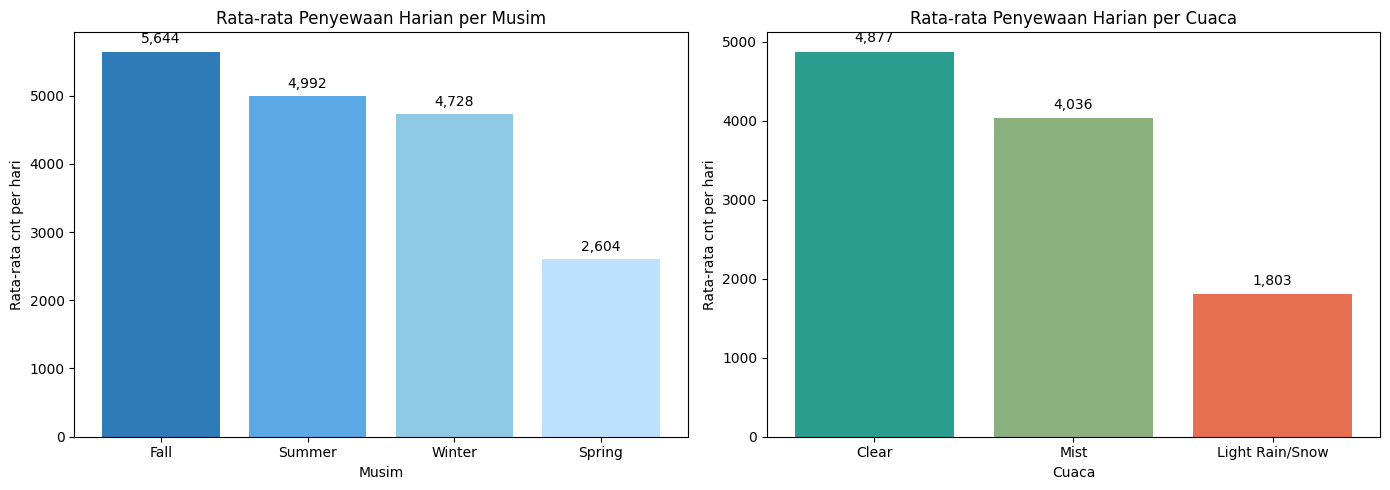

In [10]:
season_order = ['Fall', 'Summer', 'Winter', 'Spring']
season_cnt = day_df.groupby('season_label')['cnt'].mean().reindex(season_order)

weather_order = ['Clear', 'Mist', 'Light Rain/Snow']
weather_cnt = day_df.groupby('weather_label')['cnt'].mean().reindex(weather_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(season_cnt.index, season_cnt.values, color=['#2f7ab8', '#5aa9e6', '#8ecae6', '#bde0fe'])
axes[0].set_title('Rata-rata Penyewaan Harian per Musim')
axes[0].set_xlabel('Musim')
axes[0].set_ylabel('Rata-rata cnt per hari')
for i, v in enumerate(season_cnt.values):
    axes[0].text(i, v + 120, f'{v:,.0f}', ha='center')

axes[1].bar(weather_cnt.index, weather_cnt.values, color=['#2a9d8f', '#8ab17d', '#e76f51'])
axes[1].set_title('Rata-rata Penyewaan Harian per Cuaca')
axes[1].set_xlabel('Cuaca')
axes[1].set_ylabel('Rata-rata cnt per hari')
for i, v in enumerate(weather_cnt.values):
    axes[1].text(i, v + 120, f'{v:,.0f}', ha='center')

plt.tight_layout()
plt.show()

### Pertanyaan 2:

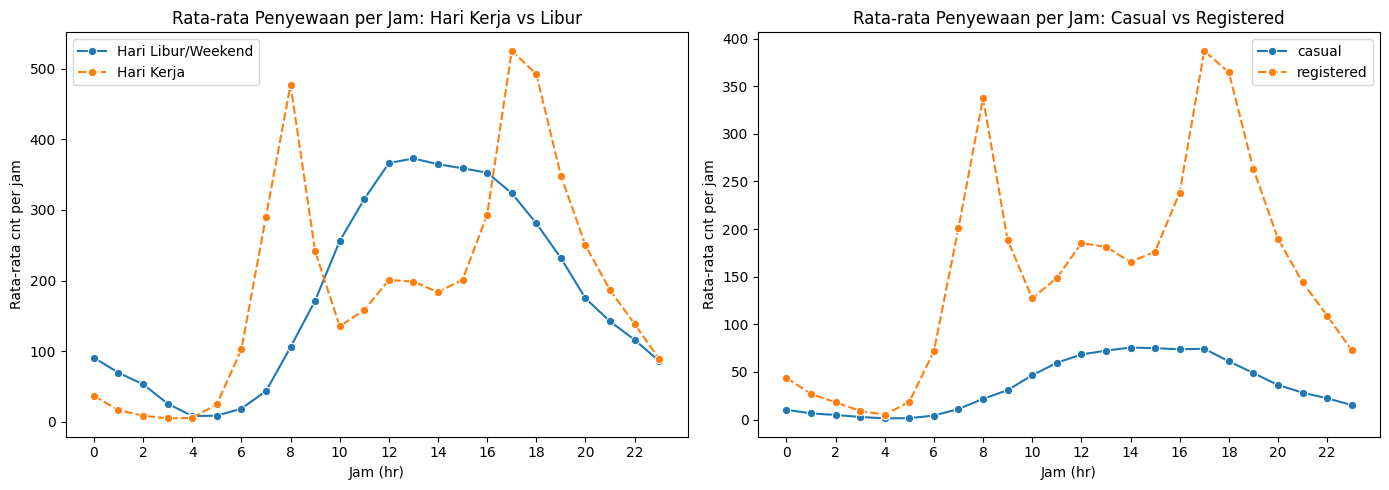

In [11]:
hourly = hour_df.groupby(['workingday', 'hr'])['cnt'].mean().unstack(0)
hourly.columns = ['Hari Libur/Weekend', 'Hari Kerja']

user_hourly = hour_df.groupby('hr')[['casual', 'registered']].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=hourly, ax=axes[0], marker='o')
axes[0].set_title('Rata-rata Penyewaan per Jam: Hari Kerja vs Libur')
axes[0].set_xlabel('Jam (hr)')
axes[0].set_ylabel('Rata-rata cnt per jam')
axes[0].set_xticks(range(0, 24, 2))

sns.lineplot(data=user_hourly, ax=axes[1], marker='o')
axes[1].set_title('Rata-rata Penyewaan per Jam: Casual vs Registered')
axes[1].set_xlabel('Jam (hr)')
axes[1].set_ylabel('Rata-rata cnt per jam')
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik Pertanyaan 1 memperjelas hasil EDA: batang Fall paling tinggi (rata-rata 5.644 penyewaan per hari), diikuti Summer 4.992 dan Winter 4.728, sedangkan Spring paling rendah (2.604) kurang dari setengah Fall. Untuk cuaca, batang Clear paling tinggi (4.877), lalu Mist (4.036), dan Light Rain/Snow paling rendah (1.803), hanya sekitar 37% dari hari cerah. Artinya, penyewaan paling ramai saat musim gugur dan cuaca cerah, dan paling sepi saat musim semi dan cuaca hujan/salju ringan.
- Grafik Pertanyaan 2 menunjukkan pola yang sangat berbeda antara hari kerja dan hari libur. Garis hari kerja (oranye) memiliki dua puncak tajam di pukul 08.00 dan 17.00, sedangkan garis hari libur/weekend (biru) hanya memiliki satu puncak yang landai di siang hari sekitar pukul 13.00. Grafik kedua menunjukkan pengguna registered selalu berada di atas casual di semua jam, dengan puncak di pukul 08.00 dan 17.00, sedangkan pengguna casual polanya lebih datar di pagi hari dan baru naik pada siang hari. Kedua jenis hari sama-sama hampir nol pada dini hari sekitar pukul 03.00–05.00.

## Analisis Lanjutan (Opsional)

Rata-rata penyewaan harian per bulan:
year    2011    2012
mnth                
1     1232.0  3121.0
2     1722.0  3556.0
3     2066.0  5319.0
4     3162.0  5807.0
5     4381.0  6318.0
6     4784.0  6761.0
7     4559.0  6568.0
8     4409.0  6919.0
9     4247.0  7286.0
10    3984.0  6414.0
11    3406.0  5089.0
12    2817.0  3991.0

Korelasi dengan cnt harian:
temp_c           0.627
atemp_c          0.631
hum_pct         -0.101
windspeed_val   -0.235
cnt              1.000
Name: cnt, dtype: float64


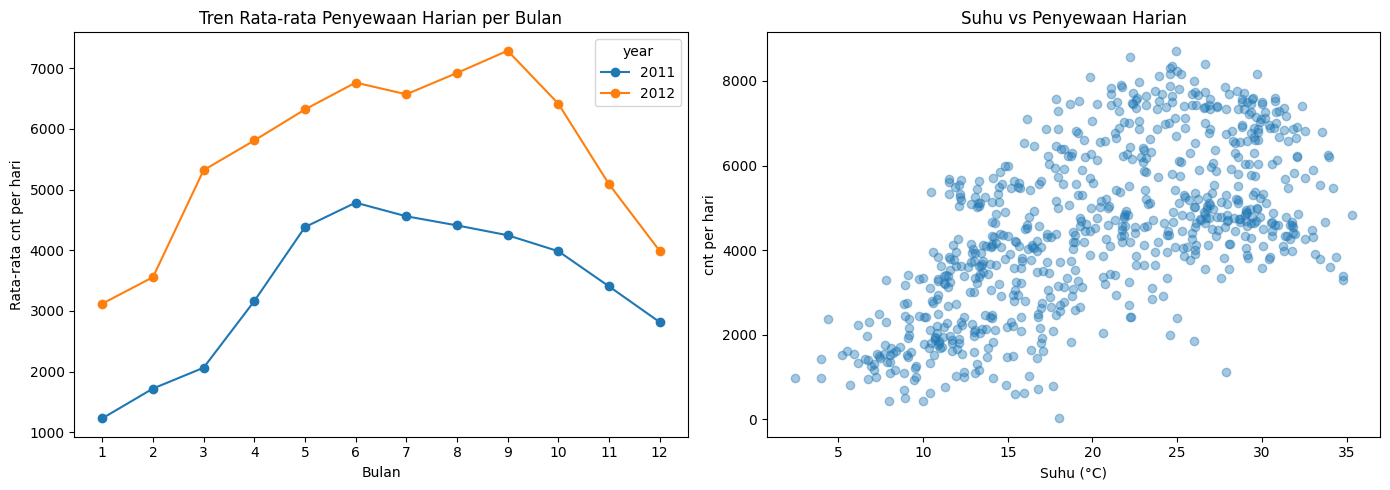

In [12]:
monthly_cnt = day_df.groupby(['year', 'mnth'])['cnt'].mean().unstack(0)

print("Rata-rata penyewaan harian per bulan:")
print(monthly_cnt.round(0))

print("\nKorelasi dengan cnt harian:")
print(day_df[['temp_c', 'atemp_c', 'hum_pct', 'windspeed_val', 'cnt']].corr()['cnt'].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly_cnt.plot(ax=axes[0], marker='o')
axes[0].set_title('Tren Rata-rata Penyewaan Harian per Bulan')
axes[0].set_xlabel('Bulan')
axes[0].set_ylabel('Rata-rata cnt per hari')
axes[0].set_xticks(range(1, 13))

axes[1].scatter(day_df['temp_c'], day_df['cnt'], alpha=0.4)
axes[1].set_title('Suhu vs Penyewaan Harian')
axes[1].set_xlabel('Suhu (°C)')
axes[1].set_ylabel('cnt per hari')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Tren bulanan menunjukkan penyewaan naik di semua bulan dari 2011 ke 2012. Kenaikan terbesar terjadi pada Januari–Maret (lebih dari 100%), sedangkan pada Juni–Desember kenaikannya sekitar 41–57%. Bulan tersibuk secara keseluruhan adalah Juni (rata-rata 5.772 per hari) dan September (5.767), sedangkan bulan paling sepi adalah Januari (2.176) dan Februari (2.655). Garis 2012 (oranye) selalu berada di atas garis 2011 (biru) di grafik kiri.
- Suhu memiliki hubungan positif yang cukup kuat dengan penyewaan harian, dengan korelasi 0,627 untuk `temp_c` dan 0,631 untuk `atemp_c`. Grafik scatter di kanan juga menunjukkan pola yang sama: semakin tinggi suhunya, titik-titik penyewaan cenderung semakin tinggi. Sebaliknya, kelembapan (`hum_pct`, korelasi -0,101) dan kecepatan angin (`windspeed_val`, korelasi -0,235) hanya berhubungan lemah dan negatif dengan penyewaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Musim dan cuaca berpengaruh besar terhadap penyewaan sepeda harian di Washington D.C. selama 2011–2012. Musim Fall paling ramai dengan rata-rata 5.644 penyewaan per hari, diikuti Summer 4.992 dan Winter 4.728, sedangkan Spring paling sepi dengan rata-rata 2.604 per hari. Cuaca Clear paling ramai dengan rata-rata 4.877 per hari, lalu Mist 4.036, dan Light Rain/Snow paling sepi 1.803 per hari. Penyewaan juga naik tajam dari 2011 (rata-rata 3.406 per hari) ke 2012 (rata-rata 5.600 per hari), dan suhu berkorelasi positif cukup kuat dengan penyewaan (korelasi 0,627).
- **Conclusion pertanyaan 2:** Pola penyewaan per jam sangat berbeda antara hari kerja dan hari libur selama 2011–2012. Pada hari kerja terdapat dua puncak tajam di pukul 08.00 (rata-rata 477 per jam) dan 17.00 (525 per jam) yang didominasi pengguna registered — contohnya pukul 08.00, registered 455 berbanding casual 22. Pada hari libur/weekend puncaknya tunggal di siang hari, pukul 13.00 (rata-rata 373 per jam), dan pengguna casual jauh lebih banyak — contohnya pukul 12.00, casual 126 berbanding registered 240. Jam paling sepi di kedua jenis hari adalah dini hari sekitar pukul 04.00.

**Rekomendasi Action Item:**
- Tambah stok dan lakukan redistribusi sepeda sebelum jam sibuk hari kerja (07.00–08.00 dan 16.00–17.00), terutama di stasiun dekat perkantoran dan kampus, serta kurangi stok pada dini hari (03.00–05.00) saat penyewaan hampir nol.
- Siapkan stok lebih banyak menjelang musim Fall dan saat cuaca diprakirakan cerah, serta siapkan rencana cadangan saat cuaca diprakirakan hujan/salju ringan, karena penyewaan bisa turun sampai sekitar 63% dibanding hari cerah.
- Buat promo siang hari libur/weekend (10.00–15.00) yang menyasar pengguna casual, misalnya tarif hemat di jam tersebut, karena pada jam itu pengguna casual paling banyak dan polanya berbeda dari hari kerja.
- Dorong pengguna casual menjadi registered melalui paket langganan bulanan, karena pengguna registered menyumbang 81,2% dari total penyewaan dan mendominasi jam sibuk hari kerja.